In [ ]:
# ==========================================================
# IMPORT LIBRARIES
# ==========================================================

import os
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

In [ ]:
# ==========================================================
# FILE PATHS
# ==========================================================

# Input Files
MASTER_FILE = "/content/drive/MyDrive/Exoplanet_Dataset/08_Master_Pipeline/Master_Pipeline.csv"

TRANSIT_FILE = "/content/drive/MyDrive/Exoplanet_Dataset/09_Transit_Features/Transit_Features.csv"

PHYSICS_FILE = "/content/drive/MyDrive/Exoplanet_Dataset/10_Physics_Features/Physics_Features.csv"

# Output Folder
OUTPUT_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset"

os.makedirs(

    OUTPUT_FOLDER,

    exist_ok=True

)

# Output File
TRAINING_FILE = os.path.join(

    OUTPUT_FOLDER,

    "Training_Dataset.csv"

)

print("=" * 60)
print("PATHS LOADED")
print("=" * 60)

print("Master   :", MASTER_FILE)
print("Transit  :", TRANSIT_FILE)
print("Physics  :", PHYSICS_FILE)
print("Output   :", TRAINING_FILE)

PATHS LOADED
Master   : /content/drive/MyDrive/Exoplanet_Dataset/08_Master_Pipeline/Master_Pipeline.csv
Transit  : /content/drive/MyDrive/Exoplanet_Dataset/09_Transit_Features/Transit_Features.csv
Physics  : /content/drive/MyDrive/Exoplanet_Dataset/10_Physics_Features/Physics_Features.csv
Output   : /content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset/Training_Dataset.csv


In [ ]:
# ==========================================================
# CREATE OUTPUT FILE
# ==========================================================

if not os.path.exists(TRAINING_FILE):

    pd.DataFrame().to_csv(

        TRAINING_FILE,

        index=False

    )

print("=" * 60)
print("OUTPUT FILE READY")
print("=" * 60)

OUTPUT FILE READY


In [ ]:
# ==========================================================
# LOAD DATASETS
# ==========================================================

master = pd.read_csv(MASTER_FILE)

transit = pd.read_csv(TRANSIT_FILE)

physics = pd.read_csv(PHYSICS_FILE)

print("=" * 60)
print("DATASETS LOADED")
print("=" * 60)

print()

print(f"Master   : {master.shape}")
print(f"Transit  : {transit.shape}")
print(f"Physics  : {physics.shape}")

print()

print("Duplicate TIC IDs")

print(f"Master   : {master['TIC_ID'].duplicated().sum()}")
print(f"Transit  : {transit['TIC_ID'].duplicated().sum()}")
print(f"Physics  : {physics['TIC_ID'].duplicated().sum()}")

DATASETS LOADED

Master   : (1172, 10)
Transit  : (1172, 8)
Physics  : (1172, 8)

Duplicate TIC IDs
Master   : 0
Transit  : 0
Physics  : 0


In [ ]:
# ==========================================================
# DATASET COLUMNS
# ==========================================================

print("=" * 60)
print("MASTER COLUMNS")
print("=" * 60)

print(master.columns.tolist())

print()

print("=" * 60)
print("TRANSIT COLUMNS")
print("=" * 60)

print(transit.columns.tolist())

print()

print("=" * 60)
print("PHYSICS COLUMNS")
print("=" * 60)

print(physics.columns.tolist())

MASTER COLUMNS
['TIC_ID', 'Label', 'Number_of_Sectors', 'Best_Sector', 'period_days', 'duration_days', 'epoch_days', 'bls_depth', 'bls_power', 'peak_sigma']

TRANSIT COLUMNS
['TIC_ID', 'depth_ppm', 'T_tot_hours', 'T_in_hours', 'duration_phase', 'ingress_phase', 'red_chi2', 'rms_resid']

PHYSICS COLUMNS
['TIC_ID', 'ingress_fraction', 'flat_bottom_fraction', 'transit_snr', 'odd_even_ratio', 'secondary_depth', 'secondary_snr', 'duty_cycle']


In [ ]:
# ==========================================================
# MERGE ALL DATASETS
# ==========================================================

dataset = (

    master

    .merge(

        transit,

        on="TIC_ID",

        how="inner"

    )

    .merge(

        physics,

        on="TIC_ID",

        how="inner"

    )

)

# ----------------------------------------------------------
# Sort
# ----------------------------------------------------------

dataset = dataset.sort_values(

    "TIC_ID"

).reset_index(

    drop=True

)

print("=" * 60)
print("TRAINING DATASET CREATED")
print("=" * 60)

print()

print("Rows    :", len(dataset))
print("Columns :", len(dataset.columns))

print()

display(dataset.head())

TRAINING DATASET CREATED

Rows    : 1172
Columns : 24



,TIC_ID,Label,Number_of_Sectors,Best_Sector,period_days,duration_days,epoch_days,bls_depth,bls_power,peak_sigma,...,ingress_phase,red_chi2,rms_resid,ingress_fraction,flat_bottom_fraction,transit_snr,odd_even_ratio,secondary_depth,secondary_snr,duty_cycle
0,737546,EB,1,5,3.079013,0.183,1441.146152,0.176721,6.905140e+06,9.223567,...,0.029717,1520.997363,0.057988,0.316427,0.367147,4.386221,1.096883,30812.446592,0.938785,0.093915
1,927579,EB,3,8,7.313719,0.138,1522.313799,0.007182,9.297943e+01,4.108305,...,0.002863,0.965778,0.007335,0.140704,0.718592,0.868916,NaN,403.933092,0.056066,0.020348
2,1528696,Planet,3,98,0.881897,0.030,3994.614357,0.007043,7.459962e+02,43.508619,...,0.014395,0.996197,0.016563,0.385253,0.229493,0.381656,1.010677,417.090013,0.025352,0.037364
3,1950736,False Positive,2,73,0.777963,0.210,3285.981604,0.000118,2.110125e+01,7.311826,...,0.134968,0.982580,0.001067,0.431389,0.137221,0.107664,5.257057,0.000000,0.000000,0.312868
4,2234723,EB,9,43,0.616019,0.249,2474.387552,0.003113,2.089008e+05,25.419678,...,0.196293,18.013362,0.001676,0.439327,0.121346,2.430875,1.240329,0.000000,0.000000,0.446803


In [ ]:
# ==========================================================
# DATASET VALIDATION
# ==========================================================

print("=" * 60)
print("DATASET VALIDATION")
print("=" * 60)

print()

print("Duplicate TIC IDs")

print(dataset["TIC_ID"].duplicated().sum())

print()

print("Class Distribution")

print(dataset["Label"].value_counts())

print()

print("Missing Values")

print(dataset.isna().sum())

print()

print("Data Types")

print(dataset.dtypes)

DATASET VALIDATION

Duplicate TIC IDs
0

Class Distribution
Label
EB                400
Planet            399
False Positive    373
Name: count, dtype: int64

Missing Values
TIC_ID                    0
Label                     0
Number_of_Sectors         0
Best_Sector               0
period_days               0
duration_days             0
epoch_days                0
bls_depth                 0
bls_power                 0
peak_sigma                0
depth_ppm                 0
T_tot_hours               0
T_in_hours                0
duration_phase            0
ingress_phase             0
red_chi2                  0
rms_resid                 0
ingress_fraction          0
flat_bottom_fraction      0
transit_snr              12
odd_even_ratio          137
secondary_depth          21
secondary_snr            21
duty_cycle                0
dtype: int64

Data Types
TIC_ID                    int64
Label                    object
Number_of_Sectors         int64
Best_Sector               int64
p

In [ ]:
# ==========================================================
# DATASET STATISTICS
# ==========================================================

print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

display(

    dataset.describe(

        include="all"

    )

)

DATASET SUMMARY


,TIC_ID,Label,Number_of_Sectors,Best_Sector,period_days,duration_days,epoch_days,bls_depth,bls_power,peak_sigma,...,ingress_phase,red_chi2,rms_resid,ingress_fraction,flat_bottom_fraction,transit_snr,odd_even_ratio,secondary_depth,secondary_snr,duty_cycle
count,1.172000e+03,1172,1172.000000,1172.000000,1172.000000,1172.000000,1172.000000,1172.000000,1.172000e+03,1172.000000,...,1172.000000,1172.000000,1172.000000,1172.000000,1172.000000,1160.000000,1035.000000,1151.000000,1151.000000,1172.000000
unique,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,EB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2.332153e+08,NaN,6.248294,50.909556,4.978401,0.129824,2721.908529,0.046648,2.857441e+07,13.134807,...,0.026727,1881.601776,0.016382,0.264782,0.473218,2.918503,80.453290,9723.971357,0.308530,0.086481
std,1.591498e+08,NaN,8.151572,30.108719,4.526888,0.068130,785.884628,0.150880,2.395878e+08,8.153515,...,0.039588,13080.714625,0.048137,0.122061,0.235403,3.528645,2487.785544,39539.383606,0.607251,0.112268
min,7.375460e+05,NaN,1.000000,-1.000000,0.500000,0.030000,1325.333267,0.000056,1.563895e+01,1.050674,...,0.000128,0.691930,0.000167,0.025000,0.000000,0.019568,-0.209211,0.000000,0.000000,0.002503
25%,1.229387e+08,NaN,2.000000,30.000000,1.145358,0.075000,2174.872204,0.002009,1.887091e+02,6.598968,...,0.003936,1.036765,0.001814,0.161068,0.269732,0.570595,0.944886,0.000000,0.000000,0.021980
50%,2.302209e+08,NaN,4.000000,55.000000,3.277213,0.112500,2798.477741,0.006272,1.671587e+03,11.950860,...,0.008651,1.515573,0.003820,0.289593,0.420814,1.495258,1.006150,129.446847,0.048294,0.039057
75%,3.408830e+08,NaN,7.000000,76.000000,8.146399,0.183000,3368.238898,0.028666,7.060790e+04,17.605982,...,0.032966,29.986399,0.013157,0.365134,0.677864,4.233704,1.097637,779.560872,0.217161,0.096830


In [ ]:
# ==========================================================
# SAVE TRAINING DATASET
# ==========================================================

dataset.to_csv(

    TRAINING_FILE,

    index=False

)

print("=" * 60)
print("TRAINING DATASET SAVED")
print("=" * 60)

print(TRAINING_FILE)

TRAINING DATASET SAVED
/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset/Training_Dataset.csv


In [ ]:
# ==========================================================
# FINAL VERIFICATION
# ==========================================================

training = pd.read_csv(TRAINING_FILE)

print("=" * 60)
print("FINAL TRAINING DATASET")
print("=" * 60)

print()

print("Rows    :", len(training))
print("Columns :", len(training.columns))

print()

display(training.head())

print()

print("Duplicate TIC IDs :", training["TIC_ID"].duplicated().sum())

print()

print("Missing Values")

print(training.isna().sum())

FINAL TRAINING DATASET

Rows    : 1172
Columns : 24



,TIC_ID,Label,Number_of_Sectors,Best_Sector,period_days,duration_days,epoch_days,bls_depth,bls_power,peak_sigma,...,ingress_phase,red_chi2,rms_resid,ingress_fraction,flat_bottom_fraction,transit_snr,odd_even_ratio,secondary_depth,secondary_snr,duty_cycle
0,737546,EB,1,5,3.079013,0.183,1441.146152,0.176721,6.905140e+06,9.223567,...,0.029717,1520.997363,0.057988,0.316427,0.367147,4.386221,1.096883,30812.446592,0.938785,0.093915
1,927579,EB,3,8,7.313719,0.138,1522.313799,0.007182,9.297943e+01,4.108305,...,0.002863,0.965778,0.007335,0.140704,0.718592,0.868916,NaN,403.933092,0.056066,0.020348
2,1528696,Planet,3,98,0.881897,0.030,3994.614357,0.007043,7.459962e+02,43.508619,...,0.014395,0.996197,0.016563,0.385253,0.229493,0.381656,1.010677,417.090013,0.025352,0.037364
3,1950736,False Positive,2,73,0.777963,0.210,3285.981604,0.000118,2.110125e+01,7.311826,...,0.134968,0.982580,0.001067,0.431389,0.137221,0.107664,5.257057,0.000000,0.000000,0.312868
4,2234723,EB,9,43,0.616019,0.249,2474.387552,0.003113,2.089008e+05,25.419678,...,0.196293,18.013362,0.001676,0.439327,0.121346,2.430875,1.240329,0.000000,0.000000,0.446803



Duplicate TIC IDs : 0

Missing Values
TIC_ID                    0
Label                     0
Number_of_Sectors         0
Best_Sector               0
period_days               0
duration_days             0
epoch_days                0
bls_depth                 0
bls_power                 0
peak_sigma                0
depth_ppm                 0
T_tot_hours               0
T_in_hours                0
duration_phase            0
ingress_phase             0
red_chi2                  0
rms_resid                 0
ingress_fraction          0
flat_bottom_fraction      0
transit_snr              12
odd_even_ratio          137
secondary_depth          21
secondary_snr            21
duty_cycle                0
dtype: int64


In [ ]:
# ==========================================================
# CLASS DISTRIBUTION
# ==========================================================

print("=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

counts = dataset["Label"].value_counts()

print(counts)

print()

print("Percentages")

print(

    (100 * counts / len(dataset)).round(2)

)

CLASS DISTRIBUTION
Label
EB                400
Planet            399
False Positive    373
Name: count, dtype: int64

Percentages
Label
EB                34.13
Planet            34.04
False Positive    31.83
Name: count, dtype: float64


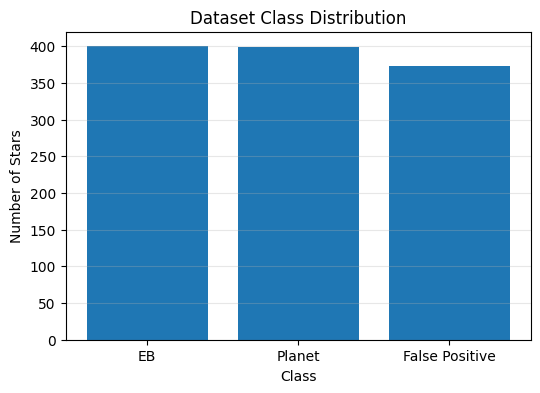

In [ ]:
# ==========================================================
# CLASS DISTRIBUTION PLOT
# ==========================================================

import matplotlib.pyplot as plt

counts = dataset["Label"].value_counts()

plt.figure(figsize=(6,4))

plt.bar(

    counts.index,

    counts.values

)

plt.xlabel("Class")

plt.ylabel("Number of Stars")

plt.title("Dataset Class Distribution")

plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# ==========================================================
# MISSING VALUE ANALYSIS
# ==========================================================

missing = pd.DataFrame({

    "Missing": dataset.isna().sum(),

    "Percent": (

        dataset.isna().mean() * 100

    ).round(2)

})

missing = missing[

    missing["Missing"] > 0

].sort_values(

    "Missing",

    ascending=False

)

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)

display(missing)

MISSING VALUE ANALYSIS


,Missing,Percent
odd_even_ratio,137,11.69
secondary_depth,21,1.79
secondary_snr,21,1.79
transit_snr,12,1.02


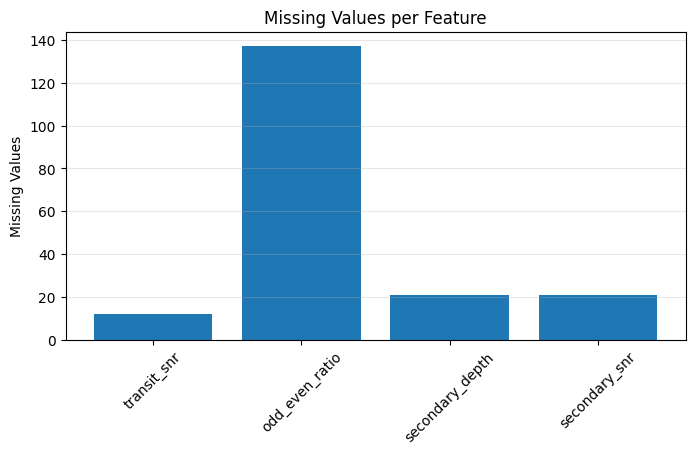

In [ ]:
# ==========================================================
# MISSING VALUE PLOT
# ==========================================================

import matplotlib.pyplot as plt

missing = dataset.isna().sum()

missing = missing[missing > 0]

plt.figure(figsize=(8,4))

plt.bar(

    missing.index,

    missing.values

)

plt.xticks(rotation=45)

plt.ylabel("Missing Values")

plt.title("Missing Values per Feature")

plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# ==========================================================
# FEATURE DISTRIBUTIONS
# ==========================================================

feature_columns = [

    "period_days",
    "duration_days",
    "bls_depth",
    "bls_power",
    "peak_sigma",

    "depth_ppm",
    "T_tot_hours",
    "T_in_hours",

    "ingress_fraction",
    "flat_bottom_fraction",

    "transit_snr",
    "odd_even_ratio",

    "secondary_depth",
    "secondary_snr",

    "duty_cycle"

]

display(

    dataset[feature_columns].describe().T

)

,count,mean,std,min,25%,50%,75%,max
period_days,1172.0,4.978401e+00,4.526888e+00,0.500000,1.145358,3.277213,8.146399,1.499758e+01
duration_days,1172.0,1.298242e-01,6.813029e-02,0.030000,0.075000,0.112500,0.183000,2.490000e-01
bls_depth,1172.0,4.664828e-02,1.508801e-01,0.000056,0.002009,0.006272,0.028666,2.930929e+00
bls_power,1172.0,2.857441e+07,2.395878e+08,15.638947,188.709098,1671.587446,70607.902412,4.572037e+09
peak_sigma,1172.0,1.313481e+01,8.153515e+00,1.050674,6.598968,11.950860,17.605982,4.350862e+01
depth_ppm,1172.0,4.856724e+04,1.080506e+05,40.874534,2046.822309,6732.400900,30037.788794,1.000000e+06
T_tot_hours,1172.0,3.998868e+00,2.484729e+00,0.489986,2.256883,3.337418,5.001565,1.195200e+01
T_in_hours,1172.0,1.026033e+00,7.707041e-01,0.039600,0.441896,0.792000,1.339188,2.988000e+00
ingress_fraction,1172.0,2.647820e-01,1.220605e-01,0.025000,0.161068,0.289593,0.365134,9.412496e-01
flat_bottom_fraction,1172.0,4.732182e-01,2.354031e-01,0.000000,0.269732,0.420814,0.677864,9.500000e-01


In [ ]:
# ==========================================================
# TOP OUTLIERS
# ==========================================================

outlier_features = [

    "odd_even_ratio",

    "secondary_depth",

    "bls_power",

    "transit_snr"

]

for feature in outlier_features:

    print("=" * 70)
    print(feature.upper())
    print("=" * 70)

    display(

        dataset[[

            "TIC_ID",

            "Label",

            feature

        ]]

        .sort_values(

            feature,

            ascending=False

        )

        .head(10)

    )

ODD_EVEN_RATIO


,TIC_ID,Label,odd_even_ratio
273,119292328,Planet,80033.490000
719,275111900,False Positive,555.148859
662,259151170,False Positive,492.792377
318,132320310,False Positive,445.913079
10,5703872,EB,284.474529
557,219151731,False Positive,59.911945
671,262746281,Planet,58.977034
963,374177909,False Positive,42.226843
646,255851356,False Positive,37.251528
1157,468828873,False Positive,31.135870


SECONDARY_DEPTH


,TIC_ID,Label,secondary_depth
517,193545440,EB,738896.960326
172,67686223,EB,330346.248588
432,159939533,EB,298352.006686
878,340704073,EB,282302.039552
1071,421110675,EB,280154.340536
564,219843981,EB,275557.385542
1116,441764197,EB,240212.311868
518,193580427,EB,239989.144525
709,272176884,EB,223670.073096
775,291320884,EB,202434.668058


BLS_POWER


,TIC_ID,Label,bls_power
387,148158540,EB,4.572037e+09
643,254003502,EB,4.003846e+09
1044,406758816,EB,3.498453e+09
583,229804573,EB,2.890242e+09
548,207085748,EB,1.484407e+09
680,266769522,EB,1.176379e+09
399,149861542,EB,1.129189e+09
112,37817410,EB,1.063380e+09
1170,1883519478,EB,8.716349e+08
302,125267683,EB,8.352120e+08


TRANSIT_SNR


,TIC_ID,Label,transit_snr
450,165721304,EB,35.423498
864,329709756,False Positive,30.830795
1131,452631268,EB,25.268026
69,27843942,EB,17.893593
40,18914916,EB,17.401584
17,8200343,EB,16.626802
595,232629077,EB,16.239780
121,42991745,EB,16.006777
538,201234926,EB,16.002813
266,117739806,EB,15.442712


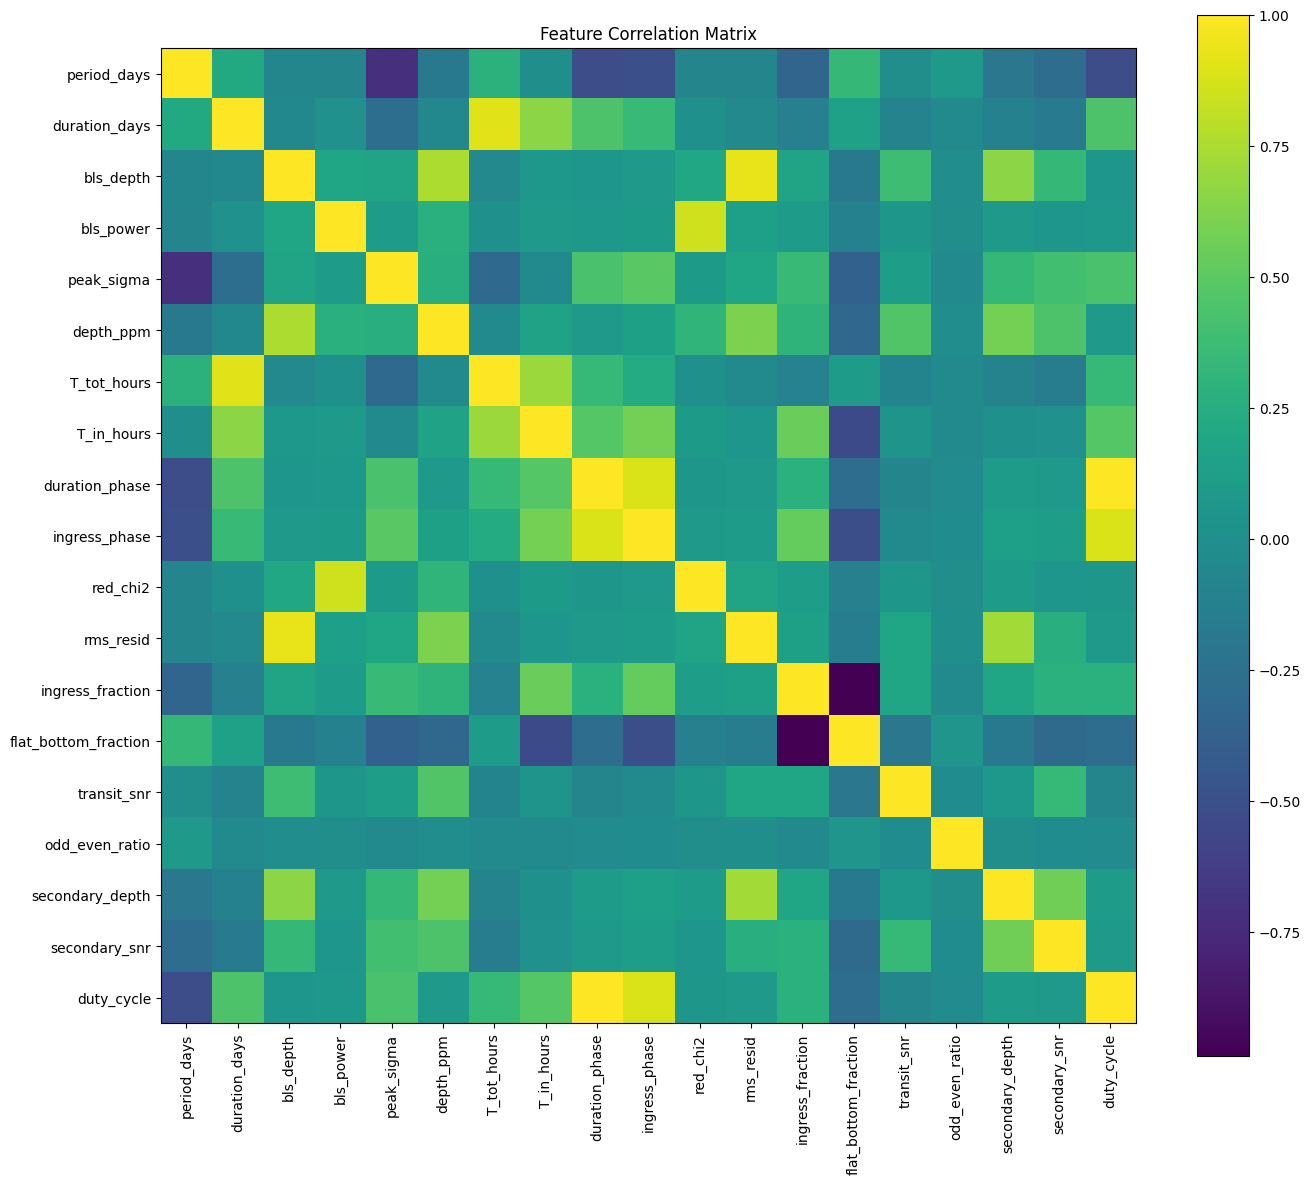

In [ ]:
# ==========================================================
# FEATURE CORRELATION MATRIX
# ==========================================================

import matplotlib.pyplot as plt

feature_columns = [

    "period_days",
    "duration_days",
    "bls_depth",
    "bls_power",
    "peak_sigma",

    "depth_ppm",
    "T_tot_hours",
    "T_in_hours",

    "duration_phase",
    "ingress_phase",

    "red_chi2",
    "rms_resid",

    "ingress_fraction",
    "flat_bottom_fraction",

    "transit_snr",
    "odd_even_ratio",

    "secondary_depth",
    "secondary_snr",

    "duty_cycle"

]

corr = dataset[feature_columns].corr(numeric_only=True)

plt.figure(figsize=(14,12))

plt.imshow(corr)

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# HIGH CORRELATION PAIRS
# ==========================================================

pairs = []

for i in range(len(corr.columns)):

    for j in range(i+1, len(corr.columns)):

        value = corr.iloc[i, j]

        if abs(value) >= 0.80:

            pairs.append({

                "Feature 1": corr.columns[i],

                "Feature 2": corr.columns[j],

                "Correlation": round(value,3)

            })

pairs = pd.DataFrame(

    pairs

).sort_values(

    "Correlation",

    key=lambda x: abs(x),

    ascending=False

)

print("="*70)
print("HIGHLY CORRELATED FEATURES")
print("="*70)

display(pairs)

HIGHLY CORRELATED FEATURES


,Feature 1,Feature 2,Correlation
4,duration_phase,duty_cycle,1.000
6,ingress_fraction,flat_bottom_fraction,-0.987
1,bls_depth,rms_resid,0.934
0,duration_days,T_tot_hours,0.910
3,duration_phase,ingress_phase,0.886
5,ingress_phase,duty_cycle,0.886
2,bls_power,red_chi2,0.854


In [ ]:
# ==========================================================
# REMOVE REDUNDANT FEATURE
# ==========================================================

import pandas as pd

dataset = pd.read_csv(TRAINING_FILE)

# Remove duration_phase
dataset = dataset.drop(columns=["duration_phase"])

# Save updated dataset
dataset.to_csv(
    TRAINING_FILE,
    index=False
)

print("=" * 60)
print("REDUNDANT FEATURE REMOVED")
print("=" * 60)

print()

print("Remaining Columns :", len(dataset.columns))

print()

print(dataset.columns.tolist())

REDUNDANT FEATURE REMOVED

Remaining Columns : 23

['TIC_ID', 'Label', 'Number_of_Sectors', 'Best_Sector', 'period_days', 'duration_days', 'epoch_days', 'bls_depth', 'bls_power', 'peak_sigma', 'depth_ppm', 'T_tot_hours', 'T_in_hours', 'ingress_phase', 'red_chi2', 'rms_resid', 'ingress_fraction', 'flat_bottom_fraction', 'transit_snr', 'odd_even_ratio', 'secondary_depth', 'secondary_snr', 'duty_cycle']
